# **Applied Data Science Project:** *Apartment Rent Predictor*
## Name: Aiden Zeigler

---

## Question I want to answer:
### - *"What factors are most important in determining the price of an apartment near Golden, Colorado?"*
### - *"What determines if a new apartment listing is undervalued or overvalued?"*

## **Step 1:** *Import required libraries*

In [72]:
# Supress warnings
import warnings
warnings.filterwarnings("ignore", category=Warning)
warnings.simplefilter(action='ignore', category=FutureWarning)

# Libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# from sklearn.ensemble import RandomForestClassifier | Which model am I using?
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import GridSearchCV
import seaborn as sns

# For API
import requests
import os
import json
from pathlib import Path

# For Data Transformation
from geopy.distance import geodesic
from sklearn.preprocessing import OneHotEncoder

## **Step 2:** *Read and load dataset*

### **SOURCE:** RentCast Rental Listings API
*Link to website:* https://developers.rentcast.io/reference/rental-listings-long-term  
API Key **(not required if listings.csv is downloaded)** is stored in *RENTCAST_API_KEY.txt*

---

We will set our focus on listings not in a specific city (or cities), but rather in a certain radius from the Colorado School of Mines campus. Therefore, we aren't capturing specific Golden, Wheatridge, or Lakewood listings, but instead any that are close enough to the school.  

The Colorado School of Mines is located at *1500 Illinois St, Golden, CO 80401*, or coordinates *(39.751022, -105.222580)*

---

**NOTE:** Will revisit the possibly of web scraping rental listing websites if time allows.
Many popular rental listing websites have scrict "anti-bot" rules that prevent me from preforming my own scrapes.

In [73]:
# RentCast has subscriptions in place for those who'd like to use their APIs.
# Therefore, if we already have the data saved, we don't send a request.
# Free / Developer plan allows for up to 50 requests / month (So don't use a request if we don't need to)
if Path("listings.csv").is_file():
    df = pd.read_csv("listings.csv")
    
else:
    # API URL
    url = "https://api.rentcast.io/v1/listings/rental/long-term"

    # Read API Key from file
    with open("RENTCAST_API_KEY.txt") as file:
        API_KEY = file.read().strip()

    # Get a response
    response = requests.get(
        url,
        headers={
            "X-Api-Key": API_KEY,
            "Accept": "application.json"
        },
        params={
            "latitude": "39.751022",        # Latitude of Mines
            "longitude": "-105.222580",     # Longitude of Mines
            "radius": "50",                 # Search for closest listings in a 50 mile radius of Mines
            "status": "Active",             # We want active, current listings
            "limit": "500",                 # Limit to 500 listings (default)
        },
        timeout=30
    )

    # Parse JSON
    listings = response.json()

    # Define fields we want to keep
    fields = ["id", "formattedAddress", "city", "state", "zipCode",
              "price", "latitude", "longitude", "bedrooms", 
              "bathrooms", "squareFootage", "propertyType",
              "status", "listedDate", "daysOnMarket"]

    # Read to pandas DataFrame
    df = pd.DataFrame([
        {field: listing.get(field) for field in fields}
        for listing in listings
    ])
    
    # Save the data to a .csv for future use
    df.to_csv("listings.csv", index=False)
    
# Print first few rows
df.head()

,id,formattedAddress,city,state,zipCode,price,latitude,longitude,bedrooms,bathrooms,squareFootage,propertyType,status,listedDate,daysOnMarket
0,"3233-Eliot-St,-Apt-211,-Denver,-CO-80211","3233 Eliot St, Apt 211, Denver, CO 80211",Denver,CO,80211,1365,39.762531,-105.024109,1,1.0,415.0,Apartment,Active,2026-10-15T00:00:00.000Z,1
1,"19672-E-49th-Ave,-Denver,-CO-80249","19672 E 49th Ave, Denver, CO 80249",Denver,CO,80249,2827,39.785152,-104.760556,3,2.5,1845.0,Single Family,Active,2026-10-15T00:00:00.000Z,1
2,"1109-N-Marion-St,-Apt-3,-Denver,-CO-80218","1109 N Marion St, Apt 3, Denver, CO 80218",Denver,CO,80218,1070,39.734043,-104.972092,1,1.0,425.0,Apartment,Active,2026-10-15T00:00:00.000Z,1
3,"2920-W-32nd-Ave,-Apt-112,-Denver,-CO-80211","2920 W 32nd Ave, Apt 112, Denver, CO 80211",Denver,CO,80211,1285,39.761635,-105.024200,1,1.0,500.0,Apartment,Active,2026-10-15T00:00:00.000Z,1
4,"2920-W-32nd-Ave,-Apt-314,-Denver,-CO-80211","2920 W 32nd Ave, Apt 314, Denver, CO 80211",Denver,CO,80211,1485,39.761635,-105.024200,1,1.0,520.0,Apartment,Active,2026-10-15T00:00:00.000Z,1


In [74]:
# Column types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                500 non-null    object 
 1   formattedAddress  500 non-null    object 
 2   city              500 non-null    object 
 3   state             500 non-null    object 
 4   zipCode           500 non-null    int64  
 5   price             500 non-null    int64  
 6   latitude          500 non-null    float64
 7   longitude         500 non-null    float64
 8   bedrooms          500 non-null    int64  
 9   bathrooms         498 non-null    float64
 10  squareFootage     489 non-null    float64
 11  propertyType      500 non-null    object 
 12  status            500 non-null    object 
 13  listedDate        500 non-null    object 
 14  daysOnMarket      500 non-null    int64  
dtypes: float64(4), int64(4), object(7)
memory usage: 58.7+ KB


## **Step 3:** Clean the Data

---

1. *Missing values:* We drop rows that contain any missing values, as we do not want to estimate square footage or # of bathrooms (Seems tricky and would rather rely on all real data).
2. *Duplicates:* No duplicates, so nothing to handle here.
3. *Outliers:* We will choose *not* to remove outliers, as we want to identify under or overvalued apartments (Could potentially remove a bargain or a rip-off). We can choose to remove outliers once we do the EDA.

In [75]:
# 1. Missing values

# Check the data for missing values
missings = df.isna().sum()
print(f"Columns with missing values: {missings}")

# Drop any columns that contain missing values
df = df.dropna()

# Verify there are no missing values
missings = df.isna().sum().sum()
print(f"Final count of missing values: {missings}")

Columns with missing values: id                   0
formattedAddress     0
city                 0
state                0
zipCode              0
price                0
latitude             0
longitude            0
bedrooms             0
bathrooms            2
squareFootage       11
propertyType         0
status               0
listedDate           0
daysOnMarket         0
dtype: int64
Final count of missing values: 0


In [76]:
# 2. Duplicates

# Check for duplicates
df[df.duplicated()]

# No duplicates, will not handle

,id,formattedAddress,city,state,zipCode,price,latitude,longitude,bedrooms,bathrooms,squareFootage,propertyType,status,listedDate,daysOnMarket


## **Step 4:** Data Engineering

---

1. *Creating features:* We create a new feature, 'distanceMines', that is the distance between Colorado School of Mines and the listing.
2. *Date processing:* We convert our 'listedDate' to datetime and only keep the month, as the year is the same for all listings.
3. *Dropping columns:* ID columns such as 'id' or 'formattedDistance' aren't relevant, so we drop them.

In [77]:
# 1. Creating features

# Coordinates of CSM
minesCoordinates = (39.751022, -105.222580)

# Calculate the distance between CSM and the listing (in miles).
df["distanceMines"] = df.apply(
    lambda row: geodesic(
        minesCoordinates,
        (row["latitude"], row["longitude"])
    ).miles,
    axis=1
)

# Print first few rows
df["distanceMines"].head()

0    10.598178
1    24.710734
2    13.392322
3    10.588961
4    10.588961
Name: distanceMines, dtype: float64

In [78]:
# 2. Date processing

# Convert 'listedDate' to datetime
df["listedDate"] = pd.to_datetime(df["listedDate"])

# Extract month only
df["listedMonth"] = df["listedDate"].dt.month

# Remove 'listedDate'
df = df.drop(columns=["listedDate"])

# Print first few rows and unique months
head = df["listedMonth"].head()
unique = df["listedMonth"].unique()
print(head, unique)
df.info()

0    10
1    10
2    10
3    10
4    10
Name: listedMonth, dtype: int32 [10  9  8]
<class 'pandas.core.frame.DataFrame'>
Index: 487 entries, 0 to 499
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                487 non-null    object 
 1   formattedAddress  487 non-null    object 
 2   city              487 non-null    object 
 3   state             487 non-null    object 
 4   zipCode           487 non-null    int64  
 5   price             487 non-null    int64  
 6   latitude          487 non-null    float64
 7   longitude         487 non-null    float64
 8   bedrooms          487 non-null    int64  
 9   bathrooms         487 non-null    float64
 10  squareFootage     487 non-null    float64
 11  propertyType      487 non-null    object 
 12  status            487 non-null    object 
 13  daysOnMarket      487 non-null    int64  
 14  distanceMines     487 non-null    float64
 15  listedMonth  

In [79]:
# 3. Dropping columns

# Drop unnecessary columns
df = df.drop(columns=["id", "formattedAddress", "state", "status"])

# Print first few rows
df.head()

,city,zipCode,price,latitude,longitude,bedrooms,bathrooms,squareFootage,propertyType,daysOnMarket,distanceMines,listedMonth
0,Denver,80211,1365,39.762531,-105.024109,1,1.0,415.0,Apartment,1,10.598178,10
1,Denver,80249,2827,39.785152,-104.760556,3,2.5,1845.0,Single Family,1,24.710734,10
2,Denver,80218,1070,39.734043,-104.972092,1,1.0,425.0,Apartment,1,13.392322,10
3,Denver,80211,1285,39.761635,-105.024200,1,1.0,500.0,Apartment,1,10.588961,10
4,Denver,80211,1485,39.761635,-105.024200,1,1.0,520.0,Apartment,1,10.588961,10


## **Step 5:** Exploratory Data Analysis

---
1. *Visualizations:* We want to create a variety of graphs, charts, and plots that help illustrate key features and trends in the data. 
2. *Summary Statistics:* We want to view descriptive statistics such as mean, median, standard deviation, and other metrics.

---

### **EDA Takeaways:**
1. Monthly rent is right-skewed.
2. Square footage is right-skewed.
3. Distance to Mines does not show a clear linear relationship.
4. While there are outliers in price and square footage, removing these points should require investigation first.
5. High rent alone does not mean that a rental listing is overpriced.

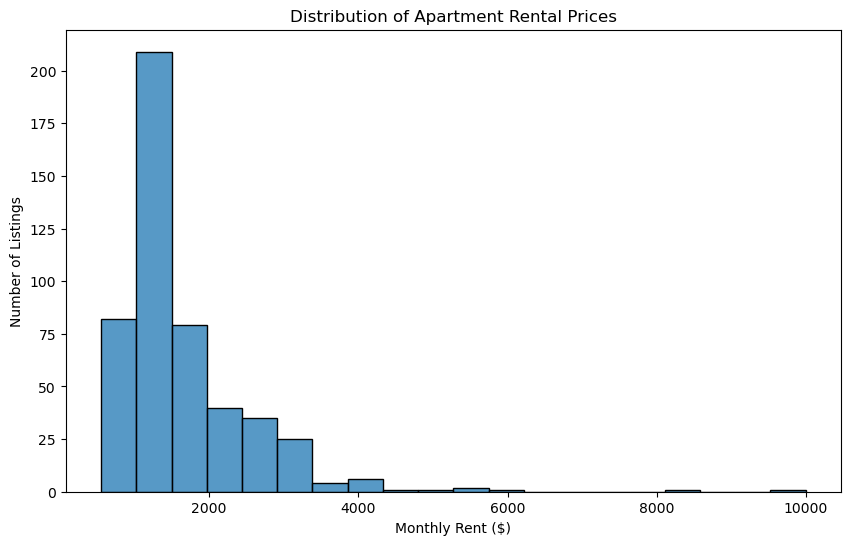

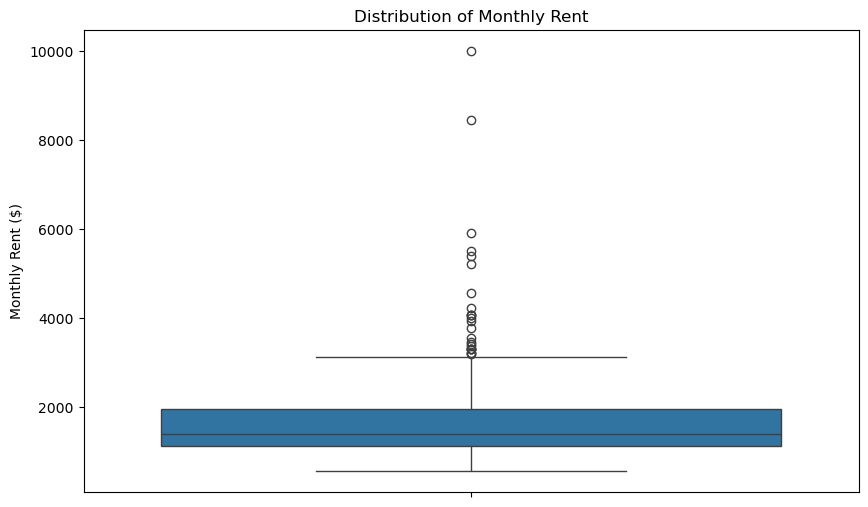

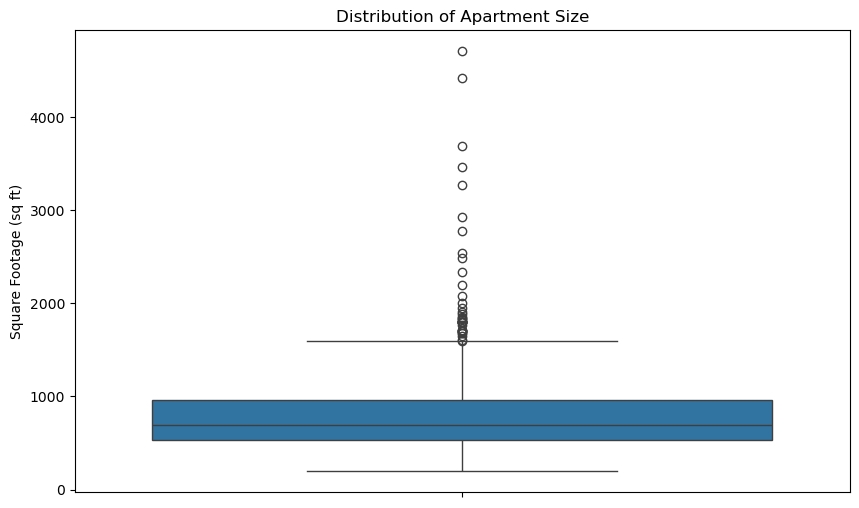

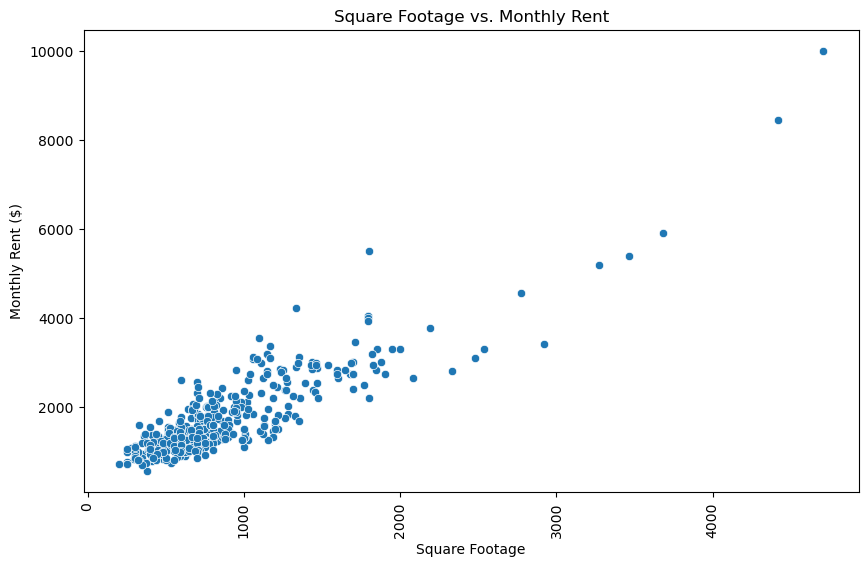

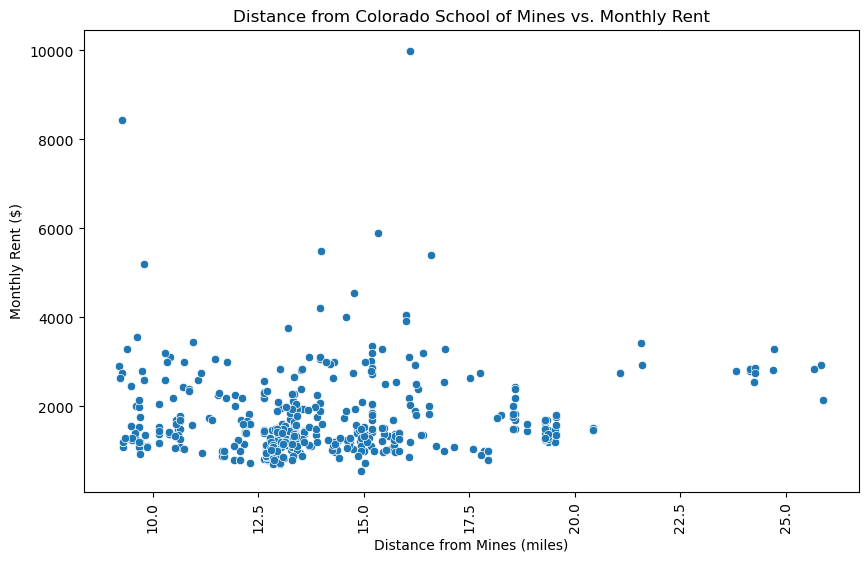

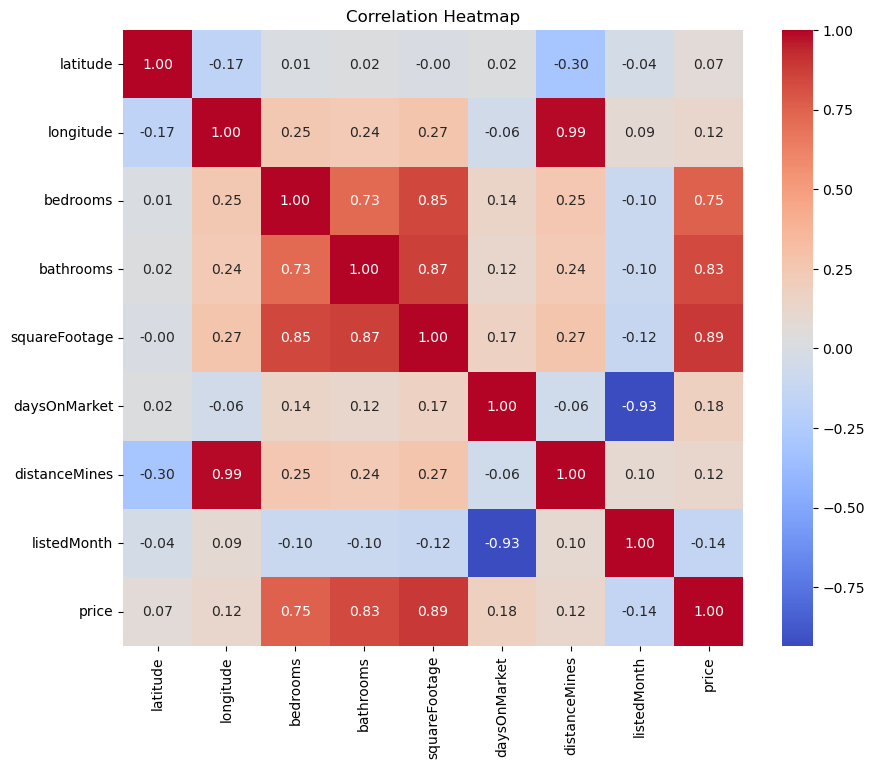

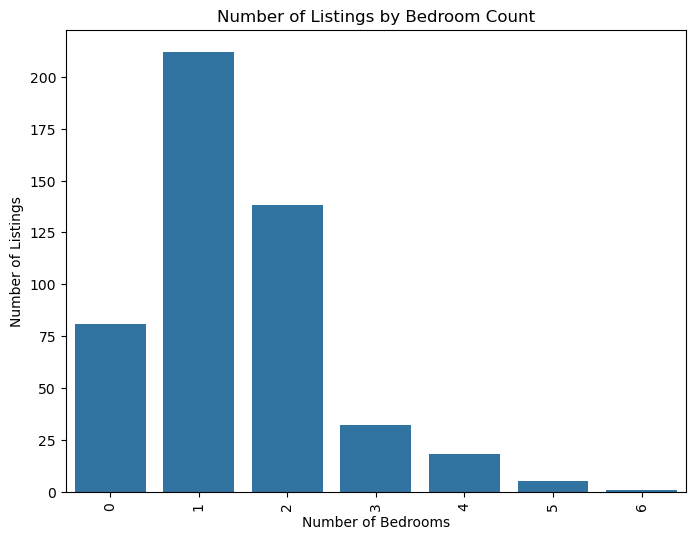

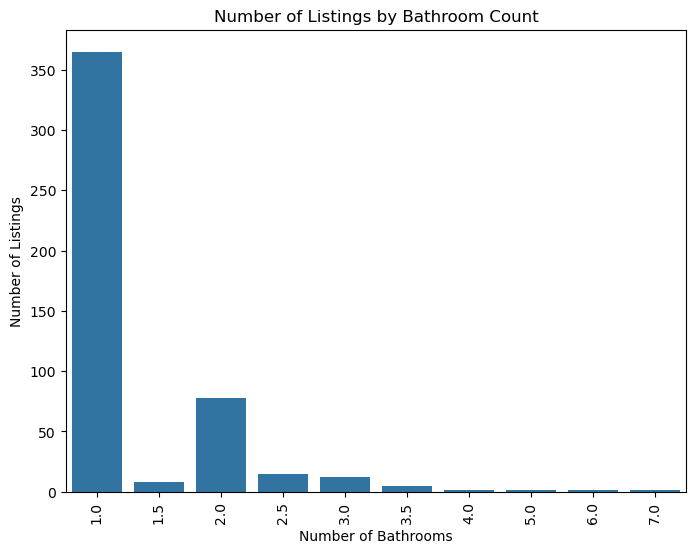

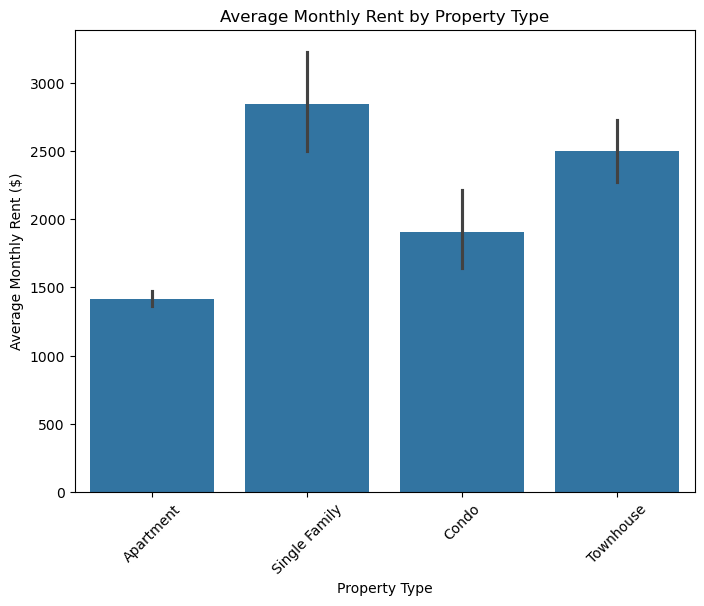

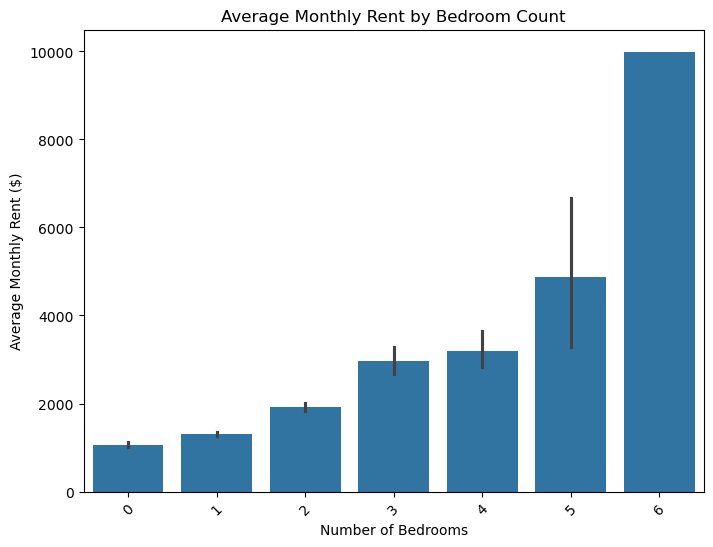

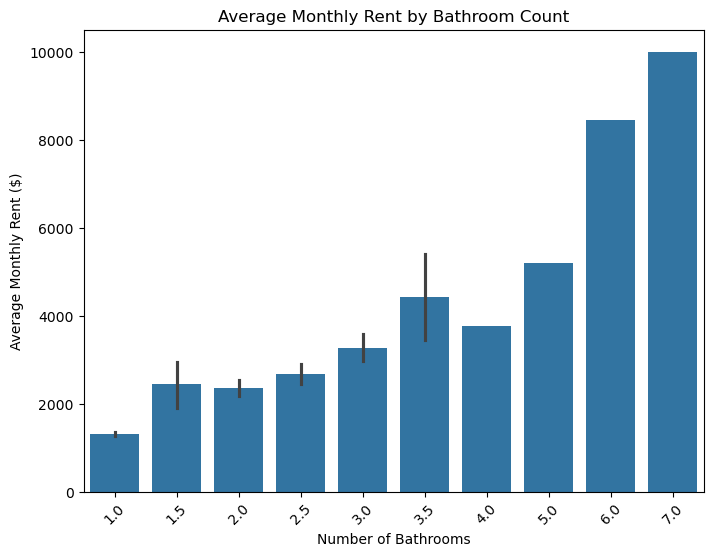

In [80]:
# 1. Visualizations

# Define numerical columns
numerical = ["latitude", "longitude", "bedrooms", "bathrooms", "squareFootage",
             "daysOnMarket", "distanceMines", "listedMonth", "price"]

# Define categorical columns
categorical = ["city", "zipCode", "propertyType"]

# Histogram to visualize distribution of monthly rent
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="price", bins=20)
plt.title("Distribution of Apartment Rental Prices")
plt.xlabel("Monthly Rent ($)")
plt.ylabel("Number of Listings")
plt.show()

# Box plot to visualize distribution of monthly rent and outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=df['price'])
plt.title('Distribution of Monthly Rent')
plt.ylabel('Monthly Rent ($)')
plt.xticks(rotation=90)
plt.show()

# Box plot to visualize distribution of square footage
plt.figure(figsize=(10, 6))
sns.boxplot(data=df['squareFootage'])
plt.title('Distribution of Apartment Size')
plt.ylabel('Square Footage (sq ft)')
plt.xticks(rotation=90)
plt.show()

# Scatter plot to visualize relationship between square footage and monthly rent
plt.figure(figsize=(10, 6))
sns.scatterplot(x='squareFootage', y='price', data=df)
plt.title('Square Footage vs. Monthly Rent')
plt.xlabel('Square Footage')
plt.ylabel('Monthly Rent ($)')
plt.xticks(rotation=90)
plt.show()

# Scatter plot to visualize relationship between distance to Mines and monthly rent
plt.figure(figsize=(10, 6))
sns.scatterplot(x='distanceMines', y='price', data=df)
plt.title('Distance from Colorado School of Mines vs. Monthly Rent')
plt.xlabel('Distance from Mines (miles)')
plt.ylabel('Monthly Rent ($)')
plt.xticks(rotation=90)
plt.show()

# Heatmap to visualize the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(data=df[numerical].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Count plot to visualize frequency of bedrooms
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='bedrooms')
plt.title('Number of Listings by Bedroom Count')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Number of Listings')
plt.xticks(rotation=90)
plt.show()

# Count plot to visualize frequency of bathrooms
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='bathrooms')
plt.title('Number of Listings by Bathroom Count')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Number of Listings')
plt.xticks(rotation=90)
plt.show()

# Bar plot to compare the property type against the mean of the monthly rent
plt.figure(figsize=(8, 6))
sns.barplot(x='propertyType', y='price', data = df, estimator='mean')
plt.xticks(rotation=45)
plt.title('Average Monthly Rent by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Average Monthly Rent ($)')
plt.show()

# Bar plot to compare the number of bedrooms against the mean of the monthly rent
plt.figure(figsize=(8, 6))
sns.barplot(x='bedrooms', y='price', data = df, estimator='mean')
plt.xticks(rotation=45)
plt.title('Average Monthly Rent by Bedroom Count')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average Monthly Rent ($)')
plt.show()

# Bar plot to compare the number of bathrooms against the mean of the monthly rent
plt.figure(figsize=(8, 6))
sns.barplot(x='bathrooms', y='price', data = df, estimator='mean')
plt.xticks(rotation=45)
plt.title('Average Monthly Rent by Bathroom Count')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Average Monthly Rent ($)')
plt.show()

In [81]:
# 2. Summary Statistics

# Describe
print(df.describe())

            zipCode        price    latitude   longitude    bedrooms  \
count    487.000000   487.000000  487.000000  487.000000  487.000000   
mean   80211.876797  1674.556468   39.722473 -104.963496    1.410678   
std       24.588657   928.547089    0.034871    0.054794    1.046122   
min    80014.000000   555.000000   39.626709 -105.095407    0.000000   
25%    80205.000000  1122.500000   39.701778 -104.986984    1.000000   
50%    80211.000000  1387.000000   39.733200 -104.974426    1.000000   
75%    80220.000000  1942.500000   39.741322 -104.941330    2.000000   
max    80249.000000  9995.000000   39.803504 -104.737623    6.000000   

        bathrooms  squareFootage  daysOnMarket  distanceMines  listedMonth  
count  487.000000     487.000000    487.000000     487.000000   487.000000  
mean     1.326489     831.663244      3.188912      14.119889     9.950719  
std      0.683564     524.455545      7.233982       3.040967     0.267657  
min      1.000000     200.000000      1.000

## **Step 6:** Data Transformation

---
1. *Train-test-split:* Split the data into training and testing sets
2. *Standardize:* We standardize the numerical columns to prepare for the model.
3. *One-hot encode:* We one-hot encode the catagorical columns to prepare for the model.

In [82]:
# 1. Train-test-split

# Define features and target
X = df.drop(columns="price")
y = df["price"]

# Train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [83]:
# 2. Standardize

# Numerical without price
features = [col for col in numerical if col != 'price']

# Standardize
scaler = StandardScaler()
X_train[features] = scaler.fit_transform(X_train[features])
X_test[features] = scaler.transform(X_test[features])

# Verify testing set
X_train

,city,zipCode,latitude,longitude,bedrooms,bathrooms,squareFootage,propertyType,daysOnMarket,distanceMines,listedMonth
425,Denver,80223,-1.163167,-0.890409,0.598723,-0.460944,-0.205831,Single Family,-0.169396,-0.649308,0.175007
319,Denver,80237,-2.442394,1.269684,-0.355798,-0.460944,0.136701,Apartment,-0.316156,1.652214,0.175007
25,Denver,80206,0.394217,0.330711,-0.355798,-0.460944,-0.367023,Apartment,-0.316156,0.227304,0.175007
226,Denver,80206,0.013211,0.334648,-0.355798,-0.460944,-0.238803,Apartment,-0.316156,0.259409,0.175007
303,Denver,80211,0.835866,-1.056505,-0.355798,-0.460944,-0.595989,Apartment,-0.169396,-1.116216,0.175007
...,...,...,...,...,...,...,...,...,...,...,...
106,Denver,80203,0.279268,-0.327110,-0.355798,-0.460944,-0.403658,Apartment,-0.316156,-0.396001,0.175007
275,Denver,80209,-0.384261,0.368058,0.598723,0.956505,0.389480,Apartment,0.417643,0.339548,0.175007
353,Denver,80206,0.493728,0.018576,-1.310320,-0.460944,-0.815796,Apartment,-0.316156,-0.076821,0.175007
446,Denver,80206,0.300157,0.400795,0.598723,-0.460944,-0.138058,Apartment,-0.169396,0.299791,0.175007


In [84]:
# 3. One-hot encode

# One-hot encode
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

# Encode
encoded_train = encoder.fit_transform(X_train[categorical])
encoded_test = encoder.transform(X_test[categorical])

# Verify testing set
encoded_train

array([[1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]])

## **Step 7:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 8:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 9:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 10:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 11:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 12:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 13:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 14:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 15:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 16:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 17:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 18:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 19:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 20:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 21:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 22:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 23:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

## **Step 24:** _

---

1. *Step1:* 
2. *Step2:* 
3. *Step3:* 
4. *Step4:*

# **CONCLUSION:**